In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.constants import c, h, e
from scipy.odr import ODR, Model, RealData
from uncertainties import ufloat, correlated_values
from uncertainties import unumpy as unp
from uncertainties import umath

In [2]:
#Problem 1
materials = ["Ag", "Al", "In", "Bi"]

rho = np.array([10.49, 2.70, 7.31, 9.78])      # g/cm^3
M   = np.array([107.9, 27.0, 114.8, 209.0])    # g/mol
z   = np.array([1, 3, 1, 5e-4])

NA = 6.02214076e23      # 1/mol
e  = 1.602176634e-19    # C

# carrier density
n_cm3 = rho / M * NA * z
n_m3  = n_cm3 * 1e6

# Hall coefficient
R_H = -1 / (n_m3 * e)   # m^3/C

for mat, n, rh in zip(materials, n_m3, R_H):
    print(f"{mat}: n = {n:.3e} 1/m^3,  R_H = {rh:.3e} m^3/C")

# Problem 2d
rho = np.array([1.6e-8, 2.6e-8, 8e-8, 1.3e-6])  # Ohm m
L = 16e-3
A = 6e-3 * 2e-6
R = rho * L / A
print(R)

# Problem 2e
R_i = np.array([4, 4, 4, 4])
I_max = np.array([2, 2, 1.5, 0.5])
V_max = I_max * (R_i + R)
print(V_max)

#problem 3

I = 2.0
B = 1.1
d = 2e-6
V_H = R_H * I * B / d
for mat, vh in zip(materials, V_H):
    print(f"{mat}: V_H = {vh:.3e} V")

Ag: n = 5.855e+28 1/m^3,  R_H = -1.066e-10 m^3/C
Al: n = 1.807e+29 1/m^3,  R_H = -3.455e-11 m^3/C
In: n = 3.835e+28 1/m^3,  R_H = -1.628e-10 m^3/C
Bi: n = 1.409e+25 1/m^3,  R_H = -4.430e-07 m^3/C
[0.02133333 0.03466667 0.10666667 1.73333333]
[8.04266667 8.06933333 6.16       2.86666667]
Ag: V_H = -1.173e-04 V
Al: V_H = -3.800e-05 V
In: V_H = -1.790e-04 V
Bi: V_H = -4.873e-01 V


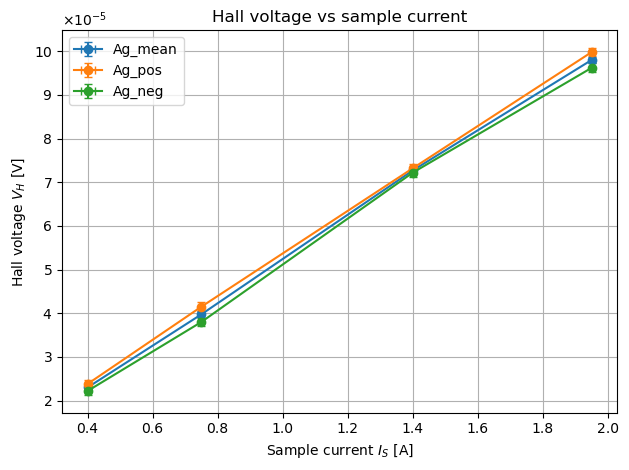

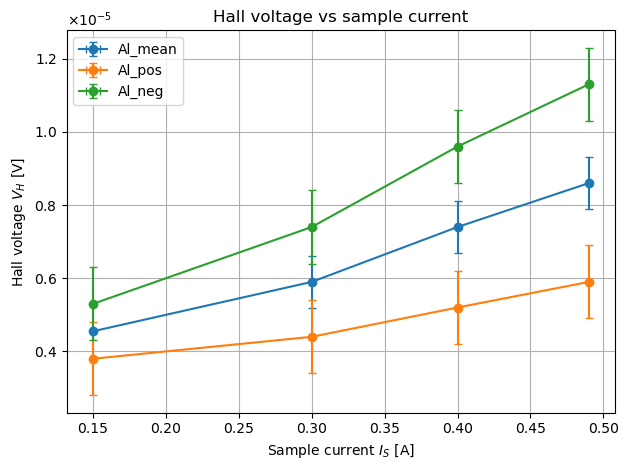

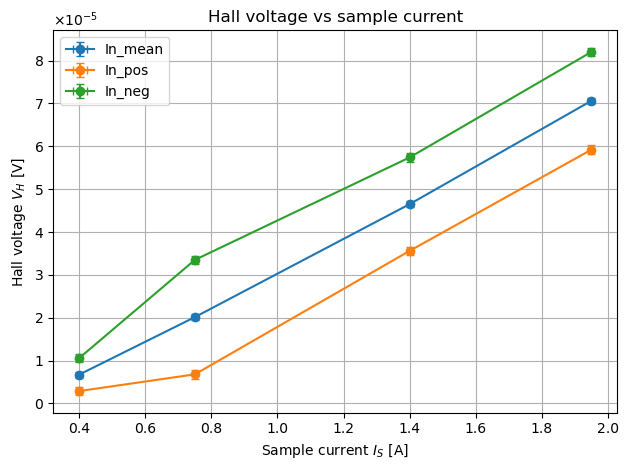

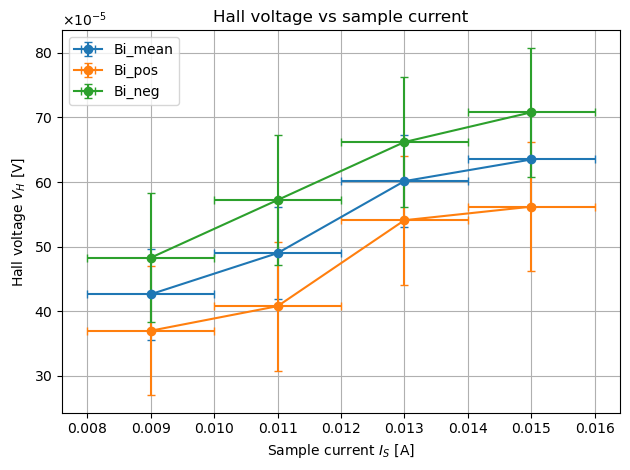

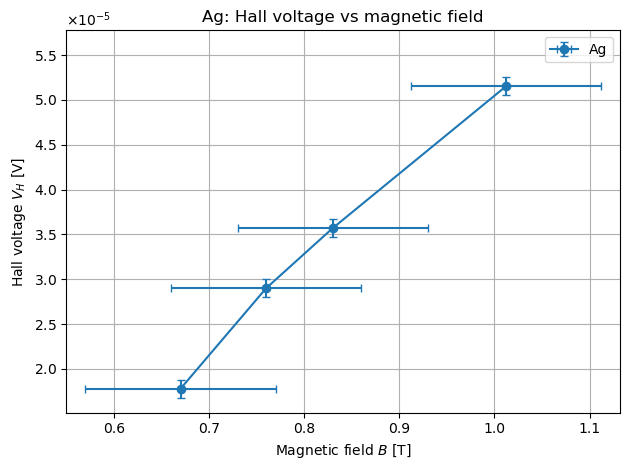

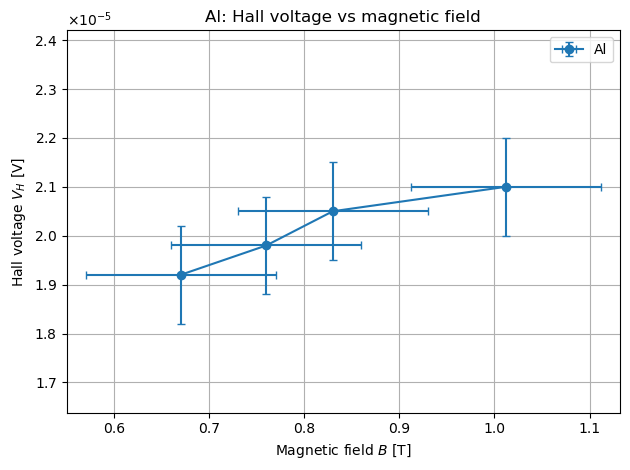

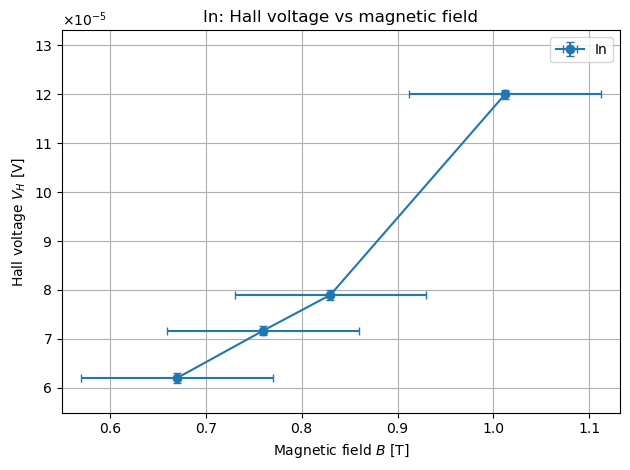

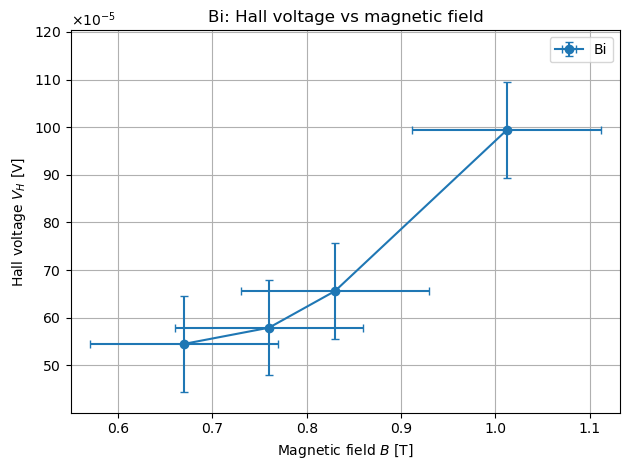

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------
#    B = constant
# -------------------

# -------- SILVER: --------
Is_Ag = np.array([1.950, 1.4, 0.75, 0.4])

Ic_Ag_p_r = np.array([9.98, 7.32, 4.15, 2.38])
Ic_Ag_p = Ic_Ag_p_r * 1e-3

Ic_Ag_n_r = np.array([9.62, 7.22, 3.80, 2.22])
Ic_Ag_n = Ic_Ag_n_r * 1e-3

R2_Ag = 0.01  # Ohm

Ic_Ag=(Ic_Ag_p+Ic_Ag_n)/2

VH_Ag = Ic_Ag * R2_Ag
VH_Ag_p = Ic_Ag_p * R2_Ag
VH_Ag_n = Ic_Ag_n * R2_Ag


# -------- ALUMINIUM --------
Is_Al = np.array([0.15,0.3,0.4,0.49,])

Ic_Al_p_r = np.array([0.38,0.44,0.52,0.59])
Ic_Al_p=Ic_Al_p_r * 1e-3

Ic_Al_n_r = np.array([0.53,0.74,0.96,1.13])
Ic_Al_n=Ic_Al_n_r * 1e-3

R2_Al = 0.01  # Ohm

Ic_Al= (Ic_Al_p+Ic_Al_n)/2

VH_Al_p = Ic_Al_p * R2_Al
VH_Al_n = Ic_Al_n * R2_Al
VH_Al = Ic_Al * R2_Al


# -------- INDIUM --------
Is_In = np.array([1.950, 1.4, 0.75, 0.4])


Ic_In_p_r = np.array([5.92,3.56,0.68,0.29])
Ic_In_p=Ic_In_p_r* 1e-3

Ic_In_n_r = np.array([8.2,5.74,3.35,1.06])
Ic_In_n=Ic_In_n_r* 1e-3

R2_In = 0.01  # Ohm

Ic_In=(Ic_In_n+Ic_In_p)/2

VH_In = Ic_In * R2_In
VH_In_n = Ic_In_n * R2_In
VH_In_p = Ic_In_p * R2_In

# -------- BISMUTH --------
Is_Bi = np.array([0.015, 0.013, 0.011, 0.009])

Ic_Bi_p_r = np.array([0.562,0.541,0.408,0.370])
Ic_Bi_p = Ic_Bi_p_r * 1e-3

Ic_Bi_n_r = np.array([0.708,0.662,0.5723,0.4830])
Ic_Bi_n = Ic_Bi_n_r * 1e-3

R2_Bi = 1 # Ohm

Ic_Bi = (Ic_Bi_n + Ic_Bi_p) / 2

VH_Bi = Ic_Bi * R2_Bi
VH_Bi_n = Ic_Bi_n * R2_Bi
VH_Bi_p = Ic_Bi_p * R2_Bi


# ============================================================
# PLOT 1: VH vs Is
# ============================================================
from matplotlib.ticker import ScalarFormatter

dIc = 0.1e-3
dIc_mean = dIc / np.sqrt(2)
dIs = 0.001

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-5, -5))


# SILVER
plt.figure()

plt.errorbar(Is_Ag, VH_Ag,
             xerr=dIs, yerr=R2_Ag*dIc_mean,
             fmt='o-', capsize=3, label='Ag_mean')

plt.errorbar(Is_Ag, VH_Ag_p,
             xerr=dIs, yerr=R2_Ag*dIc,
             fmt='o-', capsize=3, label='Ag_pos')

plt.errorbar(Is_Ag, VH_Ag_n,
             xerr=dIs, yerr=R2_Ag*dIc,
             fmt='o-', capsize=3, label='Ag_neg')

plt.xlabel('Sample current $I_S$ [A]')
plt.ylabel('Hall voltage $V_H$ [V]')
plt.gca().yaxis.set_major_formatter(formatter)
plt.title('Hall voltage vs sample current')
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("plots/data_Ag_const_B.png", dpi=180)
plt.show()


# ALUMINIUM
plt.figure()

plt.errorbar(Is_Al, VH_Al,
             xerr=dIs, yerr=R2_Al*dIc_mean,
             fmt='o-', capsize=3, label='Al_mean')

plt.errorbar(Is_Al, VH_Al_p,
             xerr=dIs, yerr=R2_Al*dIc,
             fmt='o-', capsize=3, label='Al_pos')

plt.errorbar(Is_Al, VH_Al_n,
             xerr=dIs, yerr=R2_Al*dIc,
             fmt='o-', capsize=3, label='Al_neg')

plt.xlabel('Sample current $I_S$ [A]')
plt.ylabel('Hall voltage $V_H$ [V]')
plt.gca().yaxis.set_major_formatter(formatter)
plt.title('Hall voltage vs sample current')
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("plots/data_Al_const_B.png", dpi=180)
plt.show()


# INDIUM
plt.figure()

plt.errorbar(Is_In, VH_In,
             xerr=dIs, yerr=R2_In*dIc_mean,
             fmt='o-', capsize=3, label='In_mean')

plt.errorbar(Is_In, VH_In_p,
             xerr=dIs, yerr=R2_In*dIc,
             fmt='o-', capsize=3, label='In_pos')

plt.errorbar(Is_In, VH_In_n,
             xerr=dIs, yerr=R2_In*dIc,
             fmt='o-', capsize=3, label='In_neg')

plt.xlabel('Sample current $I_S$ [A]')
plt.ylabel('Hall voltage $V_H$ [V]')
plt.gca().yaxis.set_major_formatter(formatter)
plt.title('Hall voltage vs sample current')
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("plots/data_In_const_B.png", dpi=180)
plt.show()


# BISMUTH
plt.figure()

plt.errorbar(Is_Bi, VH_Bi,
             xerr=dIs, yerr=R2_Bi*dIc_mean,
             fmt='o-', capsize=3, label='Bi_mean')

plt.errorbar(Is_Bi, VH_Bi_p,
             xerr=dIs, yerr=R2_Bi*dIc,
             fmt='o-', capsize=3, label='Bi_pos')

plt.errorbar(Is_Bi, VH_Bi_n,
             xerr=dIs, yerr=R2_Bi*dIc,
             fmt='o-', capsize=3, label='Bi_neg')

plt.xlabel('Sample current $I_S$ [A]')
plt.ylabel('Hall voltage $V_H$ [V]')
plt.gca().yaxis.set_major_formatter(formatter)
plt.title('Hall voltage vs sample current')
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("plots/data_Bi_const_B.png", dpi=180)
plt.show()

# -------------------
#    Is = constant
# -------------------

# -------- SILVER --------
B_Ag = np.array([1.012,0.830,0.760,0.670])
#8.3mm,8.5mm, 8,7mm,8.9mm

IcB_Ag = np.array([0.00515,0.00357,0.0029,0.00178])

VH_B_Ag = IcB_Ag * R2_Ag

# -------- ALUMINIUM --------

B_Al = np.array([1.012,0.830,0.760,0.670])
#8.3mm,8.5mm, 8,7mm,8.9mm

IcB_Al = np.array([0.00210,0.00205,0.00198,0.00192])

VH_B_Al = IcB_Al * R2_Al

# -------- INDIUM --------
B_In = np.array([1.012,0.830,0.760,0.670])
#8.3mm,8.5mm, 8,7mm,8.9mm

IcB_In = np.array([0.0120,0.0079,0.00717,0.0062])

VH_B_In = IcB_In * R2_In

# -------- BISMUTH --------
B_Bi = np.array([1.012,0.830,0.760,0.670])
#8.3mm,8.5mm, 8,7mm,8.9mm

IcB_Bi = np.array([0.000994,0.000656,0.000579,0.000545]) 
VH_B_Bi = IcB_Bi * R2_Bi

# ============================================================
# PLOT 2: VH vs B
# ============================================================


dB = 0.1
dIc = 0.1e-3

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-5, -5))


# SILVER
plt.figure()

plt.errorbar(B_Ag, VH_B_Ag,
             xerr=dB, yerr=R2_Ag*dIc,
             fmt='o-', capsize=3, label='Ag')

plt.xlabel('Magnetic field $B$ [T]')
plt.ylabel('Hall voltage $V_H$ [V]')
plt.gca().yaxis.set_major_formatter(formatter)

plt.xlim(min(B_Ag)-0.12, max(B_Ag)+0.12)
plt.ylim(min(VH_B_Ag-R2_Ag*dIc)*0.9,
         max(VH_B_Ag+R2_Ag*dIc)*1.1)

plt.title('Ag: Hall voltage vs magnetic field')
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("plots/data_Ag_const_I.png", dpi=180)
plt.show()


# ALUMINIUM
plt.figure()

plt.errorbar(B_Al, VH_B_Al,
             xerr=dB, yerr=R2_Al*dIc,
             fmt='o-', capsize=3, label='Al')

plt.xlabel('Magnetic field $B$ [T]')
plt.ylabel('Hall voltage $V_H$ [V]')
plt.gca().yaxis.set_major_formatter(formatter)

plt.xlim(min(B_Al)-0.12, max(B_Al)+0.12)
plt.ylim(min(VH_B_Al-R2_Al*dIc)*0.9,
         max(VH_B_Al+R2_Al*dIc)*1.1)

plt.title('Al: Hall voltage vs magnetic field')
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("plots/data_Al_const_I.png", dpi=180)
plt.show()


# INDIUM
plt.figure()

plt.errorbar(B_In, VH_B_In,
             xerr=dB, yerr=R2_In*dIc,
             fmt='o-', capsize=3, label='In')

plt.xlabel('Magnetic field $B$ [T]')
plt.ylabel('Hall voltage $V_H$ [V]')
plt.gca().yaxis.set_major_formatter(formatter)

plt.xlim(min(B_In)-0.12, max(B_In)+0.12)
plt.ylim(min(VH_B_In-R2_In*dIc)*0.9,
         max(VH_B_In+R2_In*dIc)*1.1)

plt.title('In: Hall voltage vs magnetic field')
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("plots/data_In_const_I.png", dpi=180)
plt.show()


# BISMUTH
plt.figure()

plt.errorbar(B_Bi, VH_B_Bi,
             xerr=dB, yerr=R2_Bi*dIc,
             fmt='o-', capsize=3, label='Bi')

plt.xlabel('Magnetic field $B$ [T]')
plt.ylabel('Hall voltage $V_H$ [V]')
plt.gca().yaxis.set_major_formatter(formatter)

plt.xlim(min(B_Bi)-0.12, max(B_Bi)+0.12)
plt.ylim(min(VH_B_Bi-R2_Bi*dIc)*0.9,
         max(VH_B_Bi+R2_Bi*dIc)*1.1)

plt.title('Bi: Hall voltage vs magnetic field')
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("plots/data_Bi_const_I.png", dpi=180)
plt.show()

m = (4.87+/-0.07)e-05
b = (3.6+/-0.9)e-06

Ag - VH(Is)
fit: VH = m*Is + b
RH aus I= (1.03+/-0.12)e-10 m^3/C
n aus I = (6.1+/-0.7)e+28 1/m^3
m = (9.7+/-0.6)e-05
b = (-4.6+/-0.5)e-05

Ag - VH(B)
fit: VH = m*B + b
RH aus B = (9.9+/-0.8)e-11 m^3/C
n aus B  = (6.3+/-0.5)e+28 1/m^3


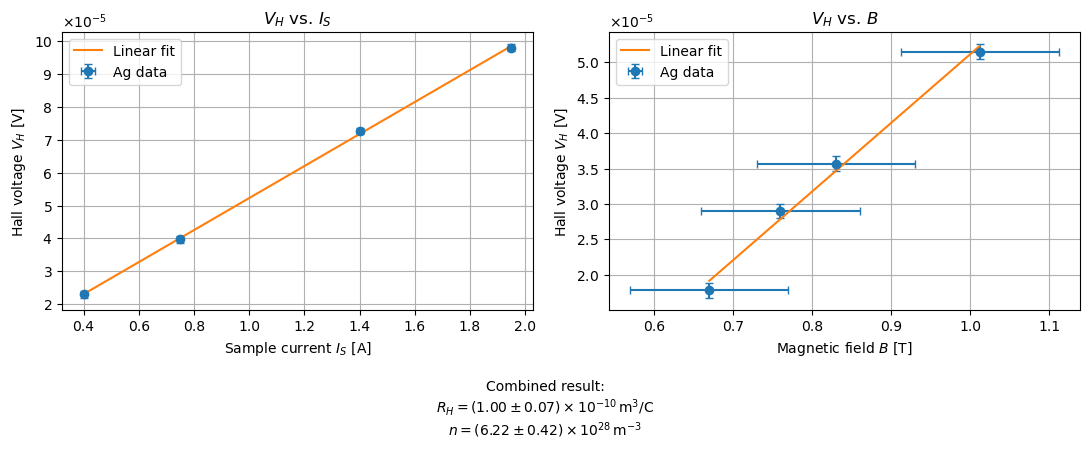

In [4]:
import numpy as np
import matplotlib.pyplot as plt

e = 1.602176634e-19


# ============================================================
# FIT 1: VH as function of Is
# ============================================================

# ---------- SILVER ----------

#---B_const---

e = 1.602176634e-19  # C

coeff, cov = np.polyfit(Is_Ag, VH_Ag, 1, cov=True)

m = ufloat(coeff[0], np.sqrt(cov[0, 0]))
b = ufloat(coeff[1], np.sqrt(cov[1, 1]))

print("m =", m)
print("b =", b)

d = ufloat(2e-6, 0.1e-6)      # m
B_const = ufloat(0.95, 0.1)   # T

RH_Ag_I = m * d / B_const
RH_abs = ufloat(abs(RH_Ag_I.n), RH_Ag_I.s)
n_Ag_I = 1 / (e * RH_abs)

print("\nAg - VH(Is)")
print("fit: VH = m*Is + b")
print("RH aus I=", RH_Ag_I, "m^3/C")
print("n aus I =", n_Ag_I, "1/m^3")

x = np.linspace(min(Is_Ag), max(Is_Ag), 200)




#---I_const---

e = 1.602176634e-19  # C

coeff, cov = np.polyfit(B_Ag, VH_B_Ag, 1, cov=True)

m = ufloat(coeff[0], np.sqrt(cov[0, 0]))
b = ufloat(coeff[1], np.sqrt(cov[1, 1]))

print("m =", m)
print("b =", b)

d = ufloat(2e-6, 0.1e-6)      # m
Is_const = ufloat(1.95, 0.01)  # A

RH_Ag_B = m * d / Is_const
RH_abs_B = ufloat(abs(RH_Ag_B.n), RH_Ag_B.s)
n_Ag_B = 1 / (e * RH_abs_B)

print("\nAg - VH(B)")
print("fit: VH = m*B + b")
print("RH aus B =", RH_Ag_B, "m^3/C")
print("n aus B  =", n_Ag_B, "1/m^3")

x = np.linspace(min(B_Ag), max(B_Ag), 200)

# weighted mean of both RH values
w_I = 1 / RH_Ag_I.s**2
w_B = 1 / RH_Ag_B.s**2

RH_Ag_mean = ufloat(
    (RH_Ag_I.n*w_I + RH_Ag_B.n*w_B) / (w_I + w_B),
    np.sqrt(1 / (w_I + w_B))
)

RH_abs_mean = ufloat(abs(RH_Ag_mean.n), RH_Ag_mean.s)
n_Ag_mean = 1 / (e * RH_abs_mean)


# fits again for plotting
coeff_I, _ = np.polyfit(Is_Ag, VH_Ag, 1, cov=True)
coeff_B, _ = np.polyfit(B_Ag, VH_B_Ag, 1, cov=True)

x_I = np.linspace(min(Is_Ag), max(Is_Ag), 200)
x_B = np.linspace(min(B_Ag), max(B_Ag), 200)


dIs = 0.001      # A
dIc = 0.1e-3     # A
dB = 0.1         # T

dVH_Ag = R2_Ag * dIc
dVH_B_Ag = R2_Ag * dIc

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))


# ---------------- VH vs Is ----------------
ax[0].errorbar(
    Is_Ag, VH_Ag,
    xerr=dIs,
    yerr=dVH_Ag,
    fmt="o",
    capsize=3,
    label="Ag data"
)

ax[0].plot(
    x_I,
    coeff_I[0]*x_I + coeff_I[1],
    "-",
    label="Linear fit"
)

ax[0].set_xlabel("Sample current $I_S$ [A]")
ax[0].set_ylabel("Hall voltage $V_H$ [V]")

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-5, -5))
ax[0].yaxis.set_major_formatter(formatter)

ax[0].set_title("$V_H$ vs. $I_S$")
ax[0].grid()
ax[0].legend()


# ---------------- VH vs B ----------------
ax[1].errorbar(
    B_Ag, VH_B_Ag,
    xerr=dB,
    yerr=dVH_B_Ag,
    fmt="o",
    capsize=3,
    label="Ag data"
)

ax[1].plot(
    x_B,
    coeff_B[0]*x_B + coeff_B[1],
    "-",
    label="Linear fit"
)

ax[1].set_xlabel("Magnetic field $B$ [T]")
ax[1].set_ylabel("Hall voltage $V_H$ [V]")

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-5, -5))
ax[1].yaxis.set_major_formatter(formatter)

ax[1].set_title("$V_H$ vs. $B$")
ax[1].grid()
ax[1].legend()


# ---------------- combined result ----------------
mean_label = (
    rf"Combined result:"
    "\n"
    rf"$R_H = ({RH_Ag_mean.n/1e-10:.2f} \pm {RH_Ag_mean.s/1e-10:.2f})"
    rf"\times10^{{-10}}\,\mathrm{{m^3/C}}$"
    "\n"
    rf"$n = ({n_Ag_mean.n/1e28:.2f} \pm {n_Ag_mean.s/1e28:.2f})"
    rf"\times10^{{28}}\,\mathrm{{m^{{-3}}}}$"
)

fig.text(
    0.5, 0.01,
    mean_label,
    ha="center",
    va="bottom"
)

plt.tight_layout(rect=[0, 0.16, 1, 1])

plt.savefig("plots/Fit_Ag_combined.png", dpi=180)
plt.show()

magnet distance and tesla measurment: 
bouth sides 8.3 cm :  1100 m T 
Unsicherheit geschätzt 50 m T



m = (1.20+/-0.10)e-05
b = (2.6+/-0.4)e-06

Al - VH(Is)
fit: VH = m*Is + b
RH aus I= (2.5+/-0.4)e-11 m^3/C
n aus I = (2.47+/-0.35)e+29 1/m^3
m = (5.2+/-1.1)e-06
b = (1.58+/-0.09)e-05

Al - VH(B)
fit: VH = m*B + b
RH aus B = (2.1+/-0.4)e-11 m^3/C
n aus B  = (2.9+/-0.6)e+29 1/m^3


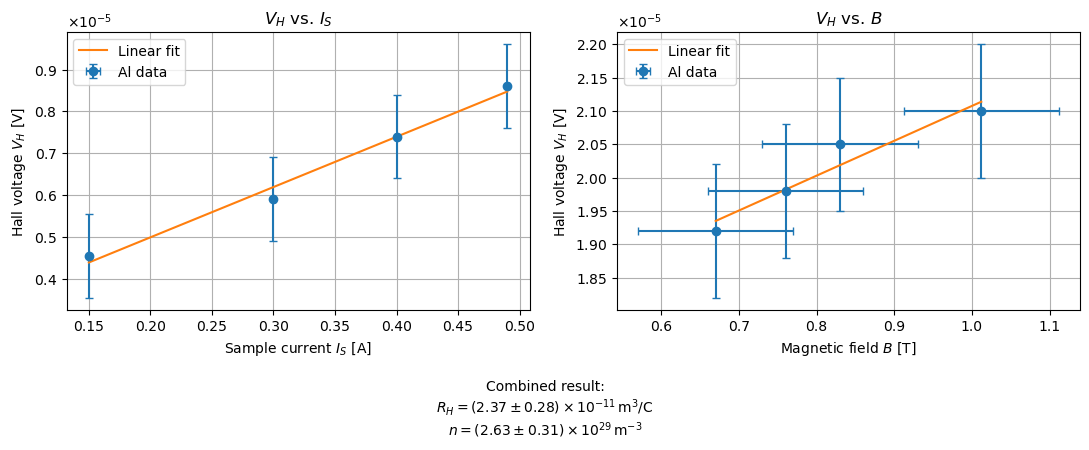

In [5]:
import numpy as np
import matplotlib.pyplot as plt

e = 1.602176634e-19


# ============================================================
# FIT 1: VH as function of Is
# ============================================================

# ---------- ALUMINIUM ----------

#---B_const---

e = 1.602176634e-19  # C

coeff, cov = np.polyfit(Is_Al, VH_Al, 1, cov=True)

m = ufloat(coeff[0], np.sqrt(cov[0, 0]))
b = ufloat(coeff[1], np.sqrt(cov[1, 1]))

print("m =", m)
print("b =", b)

d = ufloat(2e-6, 0.1e-6)      # m
B_const = ufloat(0.95, 0.1)   # T

RH_Al_I = m * d / B_const
RH_abs = ufloat(abs(RH_Al_I.n), RH_Al_I.s)
n_Al_I = 1 / (e * RH_abs)

print("\nAl - VH(Is)")
print("fit: VH = m*Is + b")
print("RH aus I=", RH_Al_I, "m^3/C")
print("n aus I =", n_Al_I, "1/m^3")

x = np.linspace(min(Is_Al), max(Is_Al), 200)




#---I_const---

e = 1.602176634e-19  # C

coeff, cov = np.polyfit(B_Al, VH_B_Al, 1, cov=True)

m = ufloat(coeff[0], np.sqrt(cov[0, 0]))
b = ufloat(coeff[1], np.sqrt(cov[1, 1]))

print("m =", m)
print("b =", b)

d = ufloat(2e-6, 0.1e-6)      # m
Is_const = ufloat(0.49, 0.01)  # A

RH_Al_B = m * d / Is_const
RH_abs_B = ufloat(abs(RH_Al_B.n), RH_Al_B.s)
n_Al_B = 1 / (e * RH_abs_B)

print("\nAl - VH(B)")
print("fit: VH = m*B + b")
print("RH aus B =", RH_Al_B, "m^3/C")
print("n aus B  =", n_Al_B, "1/m^3")

x = np.linspace(min(B_Al), max(B_Al), 200)


from matplotlib.ticker import ScalarFormatter

# ---------------- combined mean ----------------
w_I = 1 / RH_Al_I.s**2
w_B = 1 / RH_Al_B.s**2

RH_Al_mean = ufloat(
    (RH_Al_I.n*w_I + RH_Al_B.n*w_B) / (w_I + w_B),
    np.sqrt(1 / (w_I + w_B))
)

RH_abs_mean = ufloat(abs(RH_Al_mean.n), RH_Al_mean.s)
n_Al_mean = 1 / (e * RH_abs_mean)


# ---------------- fits for plotting ----------------
coeff_I, _ = np.polyfit(Is_Al, VH_Al, 1, cov=True)
coeff_B, _ = np.polyfit(B_Al, VH_B_Al, 1, cov=True)

x_I = np.linspace(min(Is_Al), max(Is_Al), 200)
x_B = np.linspace(min(B_Al), max(B_Al), 200)

# uncertainties
dIs = 0.001      # A
dIc = 0.1e-3     # A
dB = 0.1         # T

dVH_Al = R2_Al * dIc
dVH_B_Al = R2_Al * dIc

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))


# ---------------- VH vs Is ----------------
ax[0].errorbar(
    Is_Al, VH_Al,
    xerr=dIs,
    yerr=dVH_Al,
    fmt="o",
    capsize=3,
    label="Al data"
)

ax[0].plot(
    x_I,
    coeff_I[0]*x_I + coeff_I[1],
    "-",
    label="Linear fit"
)

ax[0].set_xlabel("Sample current $I_S$ [A]")
ax[0].set_ylabel("Hall voltage $V_H$ [V]")

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-5, -5))
ax[0].yaxis.set_major_formatter(formatter)

ax[0].set_title("$V_H$ vs. $I_S$")
ax[0].grid()
ax[0].legend()


# ---------------- VH vs B ----------------
ax[1].errorbar(
    B_Al, VH_B_Al,
    xerr=dB,
    yerr=dVH_B_Al,
    fmt="o",
    capsize=3,
    label="Al data"
)

ax[1].plot(
    x_B,
    coeff_B[0]*x_B + coeff_B[1],
    "-",
    label="Linear fit"
)

ax[1].set_xlabel("Magnetic field $B$ [T]")
ax[1].set_ylabel("Hall voltage $V_H$ [V]")

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-5, -5))
ax[1].yaxis.set_major_formatter(formatter)

ax[1].set_title("$V_H$ vs. $B$")
ax[1].grid()
ax[1].legend()


# ---------------- combined result ----------------
mean_label = (
    rf"Combined result:"
    "\n"
    rf"$R_H = ({RH_Al_mean.n/1e-11:.2f} \pm {RH_Al_mean.s/1e-11:.2f})"
    rf"\times10^{{-11}}\,\mathrm{{m^3/C}}$"
    "\n"
    rf"$n = ({n_Al_mean.n/1e29:.2f} \pm {n_Al_mean.s/1e29:.2f})"
    rf"\times10^{{29}}\,\mathrm{{m^{{-3}}}}$"
)

fig.text(
    0.5, 0.01,
    mean_label,
    ha="center",
    va="bottom"
)

plt.tight_layout(rect=[0, 0.16, 1, 1])

plt.savefig("plots/Fit_Al_combined.png", dpi=180)
plt.show()

m = (4.12+/-0.08)e-05
b = (-1.03+/-0.10)e-05

In - VH(Is)
fit: VH = m*Is + b
RH aus I= (8.7+/-1.0)e-11 m^3/C
n aus I = (7.2+/-0.8)e+28 1/m^3
m = 0.000173+/-0.000024
b = (-5.8+/-2.0)e-05

In - VH(B)
fit: VH = m*B + b
RH aus B = (1.77+/-0.26)e-10 m^3/C
n aus B  = (3.5+/-0.5)e+28 1/m^3


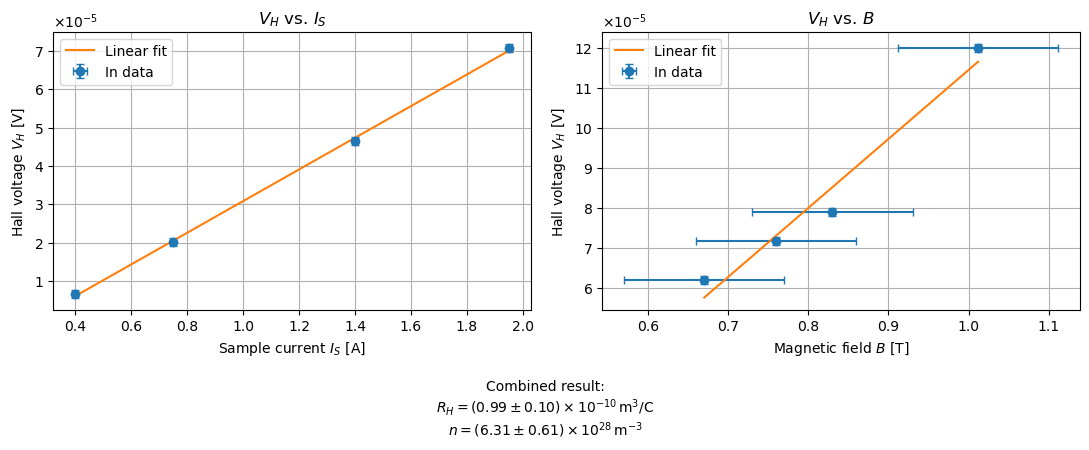

In [6]:
import numpy as np
import matplotlib.pyplot as plt

e = 1.602176634e-19


# ============================================================
# FIT 1: VH as function of Is
# ============================================================

# ---------- INDIUM ----------

#---B_const---

e = 1.602176634e-19  # C

coeff, cov = np.polyfit(Is_In, VH_In, 1, cov=True)

m = ufloat(coeff[0], np.sqrt(cov[0, 0]))
b = ufloat(coeff[1], np.sqrt(cov[1, 1]))

print("m =", m)
print("b =", b)

d = ufloat(2e-6, 0.1e-6)      # m
B_const = ufloat(0.95, 0.1)   # T

RH_In_I = m * d / B_const
RH_abs = ufloat(abs(RH_In_I.n), RH_In_I.s)
n_In_I = 1 / (e * RH_abs)

print("\nIn - VH(Is)")
print("fit: VH = m*Is + b")
print("RH aus I=", RH_In_I, "m^3/C")
print("n aus I =", n_In_I, "1/m^3")

x = np.linspace(min(Is_In), max(Is_In), 200)




#---I_const---

e = 1.602176634e-19  # C

coeff, cov = np.polyfit(B_In, VH_B_In, 1, cov=True)

m = ufloat(coeff[0], np.sqrt(cov[0, 0]))
b = ufloat(coeff[1], np.sqrt(cov[1, 1]))

print("m =", m)
print("b =", b)

d = ufloat(2e-6, 0.1e-6)      # m
Is_const = ufloat(1.95, 0.01)  # A

RH_In_B = m * d / Is_const
RH_abs_B = ufloat(abs(RH_In_B.n), RH_In_B.s)
n_In_B = 1 / (e * RH_abs_B)

print("\nIn - VH(B)")
print("fit: VH = m*B + b")
print("RH aus B =", RH_In_B, "m^3/C")
print("n aus B  =", n_In_B, "1/m^3")

x = np.linspace(min(B_In), max(B_In), 200)


from matplotlib.ticker import ScalarFormatter

# ---------------- combined mean ----------------
w_I = 1 / RH_In_I.s**2
w_B = 1 / RH_In_B.s**2

RH_In_mean = ufloat(
    (RH_In_I.n*w_I + RH_In_B.n*w_B) / (w_I + w_B),
    np.sqrt(1 / (w_I + w_B))
)

RH_abs_mean = ufloat(abs(RH_In_mean.n), RH_In_mean.s)
n_In_mean = 1 / (e * RH_abs_mean)


# ---------------- fits for plotting ----------------
coeff_I, _ = np.polyfit(Is_In, VH_In, 1, cov=True)
coeff_B, _ = np.polyfit(B_In, VH_B_In, 1, cov=True)

x_I = np.linspace(min(Is_In), max(Is_In), 200)
x_B = np.linspace(min(B_In), max(B_In), 200)

# uncertainties
dIs = 0.001      # A
dIc = 0.1e-3     # A
dB = 0.1         # T

dVH_In = R2_In * dIc
dVH_B_In = R2_In * dIc

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))


# ---------------- VH vs Is ----------------
ax[0].errorbar(
    Is_In, VH_In,
    xerr=dIs,
    yerr=dVH_In,
    fmt="o",
    capsize=3,
    label="In data"
)

ax[0].plot(
    x_I,
    coeff_I[0]*x_I + coeff_I[1],
    "-",
    label="Linear fit"
)

ax[0].set_xlabel("Sample current $I_S$ [A]")
ax[0].set_ylabel("Hall voltage $V_H$ [V]")

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-5, -5))
ax[0].yaxis.set_major_formatter(formatter)

ax[0].set_title("$V_H$ vs. $I_S$")
ax[0].grid()
ax[0].legend()


# ---------------- VH vs B ----------------
ax[1].errorbar(
    B_In, VH_B_In,
    xerr=dB,
    yerr=dVH_B_In,
    fmt="o",
    capsize=3,
    label="In data"
)

ax[1].plot(
    x_B,
    coeff_B[0]*x_B + coeff_B[1],
    "-",
    label="Linear fit"
)

ax[1].set_xlabel("Magnetic field $B$ [T]")
ax[1].set_ylabel("Hall voltage $V_H$ [V]")

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-5, -5))
ax[1].yaxis.set_major_formatter(formatter)

ax[1].set_title("$V_H$ vs. $B$")
ax[1].grid()
ax[1].legend()


# ---------------- combined result ----------------
mean_label = (
    rf"Combined result:"
    "\n"
    rf"$R_H = ({RH_In_mean.n/1e-10:.2f} \pm {RH_In_mean.s/1e-10:.2f})"
    rf"\times10^{{-10}}\,\mathrm{{m^3/C}}$"
    "\n"
    rf"$n = ({n_In_mean.n/1e28:.2f} \pm {n_In_mean.s/1e28:.2f})"
    rf"\times10^{{28}}\,\mathrm{{m^{{-3}}}}$"
)

fig.text(
    0.5, 0.01,
    mean_label,
    ha="center",
    va="bottom"
)

plt.tight_layout(rect=[0, 0.16, 1, 1])

plt.savefig("plots/Fit_In_combined.png", dpi=180)
plt.show()

m = 0.037+/-0.005
b = 0.00010+/-0.00006

Bi - VH(Is)
fit: VH = m*Is + b
RH aus I= (8.9+/-1.6)e-08 m^3/C
n aus I = (7.0+/-1.2)e+25 1/m^3
m = 0.00137+/-0.00026
b = -0.00043+/-0.00021

Bi - VH(B)
fit: VH = m*B + b
RH aus B = (2.1+/-0.4)e-07 m^3/C
n aus B  = (3.0+/-0.6)e+25 1/m^3


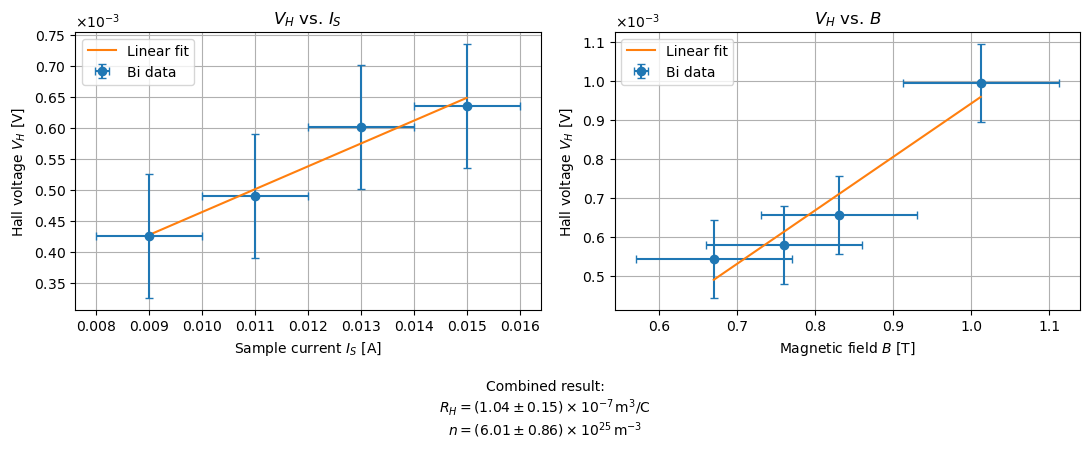

In [7]:
import numpy as np
import matplotlib.pyplot as plt

e = 1.602176634e-19


# ============================================================
# FIT 1: VH as function of Is
# ============================================================

# ---------- BISMUTH ----------

#---B_const---

e = 1.602176634e-19  # C

coeff, cov = np.polyfit(Is_Bi, VH_Bi, 1, cov=True)

m = ufloat(coeff[0], np.sqrt(cov[0, 0]))
b = ufloat(coeff[1], np.sqrt(cov[1, 1]))

print("m =", m)
print("b =", b)

d = ufloat(2.3e-6, 0.1e-6)      # m
B_const = ufloat(0.95, 0.1)      # T

RH_Bi_I = m * d / B_const
RH_abs = ufloat(abs(RH_Bi_I.n), RH_Bi_I.s)
n_Bi_I = 1 / (e * RH_abs)

print("\nBi - VH(Is)")
print("fit: VH = m*Is + b")
print("RH aus I=", RH_Bi_I, "m^3/C")
print("n aus I =", n_Bi_I, "1/m^3")

x = np.linspace(min(Is_Bi), max(Is_Bi), 200)




#---I_const---

e = 1.602176634e-19  # C

coeff, cov = np.polyfit(B_Bi, VH_B_Bi, 1, cov=True)

m = ufloat(coeff[0], np.sqrt(cov[0, 0]))
b = ufloat(coeff[1], np.sqrt(cov[1, 1]))

print("m =", m)
print("b =", b)

d = ufloat(2.3e-6, 0.1e-6)      # m
Is_const = ufloat(0.015, 0.001)   # A   # A

RH_Bi_B = m * d / Is_const
RH_abs_B = ufloat(abs(RH_Bi_B.n), RH_Bi_B.s)
n_Bi_B = 1 / (e * RH_abs_B)

print("\nBi - VH(B)")
print("fit: VH = m*B + b")
print("RH aus B =", RH_Bi_B, "m^3/C")
print("n aus B  =", n_Bi_B, "1/m^3")

x = np.linspace(min(B_Bi), max(B_Bi), 200)




from matplotlib.ticker import ScalarFormatter

# ---------------- combined mean ----------------
w_I = 1 / RH_Bi_I.s**2
w_B = 1 / RH_Bi_B.s**2

RH_Bi_mean = ufloat(
    (RH_Bi_I.n*w_I + RH_Bi_B.n*w_B) / (w_I + w_B),
    np.sqrt(1 / (w_I + w_B))
)

RH_abs_mean = ufloat(abs(RH_Bi_mean.n), RH_Bi_mean.s)
n_Bi_mean = 1 / (e * RH_abs_mean)


# ---------------- fits for plotting ----------------
coeff_I, _ = np.polyfit(Is_Bi, VH_Bi, 1, cov=True)
coeff_B, _ = np.polyfit(B_Bi, VH_B_Bi, 1, cov=True)

x_I = np.linspace(min(Is_Bi), max(Is_Bi), 200)
x_B = np.linspace(min(B_Bi), max(B_Bi), 200)


# uncertainties
dIs = 0.001      # A
dIc = 0.1e-3     # A
dB = 0.1         # T

dVH_Bi = R2_Bi * dIc
dVH_B_Bi = R2_Bi * dIc

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))


# ---------------- VH vs Is ----------------
ax[0].errorbar(
    Is_Bi, VH_Bi,
    xerr=dIs,
    yerr=dVH_Bi,
    fmt="o",
    capsize=3,
    label="Bi data"
)

ax[0].plot(
    x_I,
    coeff_I[0]*x_I + coeff_I[1],
    "-",
    label="Linear fit"
)

ax[0].set_xlabel("Sample current $I_S$ [A]")
ax[0].set_ylabel("Hall voltage $V_H$ [V]")

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-3, -3))
ax[0].yaxis.set_major_formatter(formatter)

ax[0].set_title("$V_H$ vs. $I_S$")
ax[0].grid()
ax[0].legend()


# ---------------- VH vs B ----------------
ax[1].errorbar(
    B_Bi, VH_B_Bi,
    xerr=dB,
    yerr=dVH_B_Bi,
    fmt="o",
    capsize=3,
    label="Bi data"
)

ax[1].plot(
    x_B,
    coeff_B[0]*x_B + coeff_B[1],
    "-",
    label="Linear fit"
)

ax[1].set_xlabel("Magnetic field $B$ [T]")
ax[1].set_ylabel("Hall voltage $V_H$ [V]")

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-3, -3))
ax[1].yaxis.set_major_formatter(formatter)

ax[1].set_title("$V_H$ vs. $B$")
ax[1].grid()
ax[1].legend()


# ---------------- combined result ----------------
mean_label = (
    rf"Combined result:"
    "\n"
    rf"$R_H = ({RH_Bi_mean.n/1e-7:.2f} \pm {RH_Bi_mean.s/1e-7:.2f})"
    rf"\times10^{{-7}}\,\mathrm{{m^3/C}}$"
    "\n"
    rf"$n = ({n_Bi_mean.n/1e25:.2f} \pm {n_Bi_mean.s/1e25:.2f})"
    rf"\times10^{{25}}\,\mathrm{{m^{{-3}}}}$"
)

fig.text(
    0.5, 0.01,
    mean_label,
    ha="center",
    va="bottom"
)

plt.tight_layout(rect=[0, 0.16, 1, 1])

plt.savefig("plots/Fit_Bi_combined.png", dpi=180)
plt.show()